# Pricing Walkthrough: PR 2 (`marrid_2_rates`)

Interactive walkthrough for inspecting the PR 2 domain tables (`PR_CURVE_KNOT`, `PR_CASHFLOW`), single-pass `LAG`/`LEAD` curve interpolation (`LOG_LINEAR_DF`, `LINEAR_ZERO`, `LINEAR_DF`), and DuckDB Pure execution against the Python float reference oracle.

In [1]:
import datetime as dt
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "projects" / "pricing" / "model.pure").is_file():
    REPO_ROOT = REPO_ROOT.parent

if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))
so_path = REPO_ROOT / "bazel-bin" / "native" / "libcompiler.so"
if so_path.is_file():
    os.environ.setdefault("LEGEND_LITE_LIBRARY", str(so_path))

from pricing.rack import (
    CashflowRow,
    CurveKnot,
    FraSpec,
    SwapSpec,
    build_curve_scenarios,
    compute_bump_dv01_python,
    expand_fra_to_cashflows,
    expand_swap_to_cashflows,
    fit_zero_curve,
    price_cashflows_python,
    run_pure_discount_factors_duckdb,
    run_pure_pricing_duckdb,
)

PRICING_DIR = REPO_ROOT / "projects" / "pricing"
VAL_DATE = dt.date(2026, 1, 2)
HOLIDAYS = {dt.date(2026, 1, 1), dt.date(2026, 12, 25)}
print("Using projects/pricing:", PRICING_DIR)

Using projects/pricing: /home/dunst/wk/legend-lite/projects/pricing


## Step 1: Fit `USD_OIS` Zero Curve (`PR_CURVE_KNOT`) & Verify Exact Knot Discount Factors in Pure

In [2]:
benchmarks = [
    SwapSpec("BM_6M",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,   6, 6, 1_000_000.0, 0.0410),
    SwapSpec("BM_1Y",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,  12, 6, 1_000_000.0, 0.0420),
    SwapSpec("BM_2Y",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,  24, 6, 1_000_000.0, 0.0435),
    SwapSpec("BM_3Y",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,  36, 6, 1_000_000.0, 0.0450),
    SwapSpec("BM_5Y",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,  60, 6, 1_000_000.0, 0.0470),
    SwapSpec("BM_7Y",  "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE,  84, 6, 1_000_000.0, 0.0485),
    SwapSpec("BM_10Y", "OIS", "USD", "USD_OIS", "USD_OIS", VAL_DATE, 120, 6, 1_000_000.0, 0.0500),
]
base_knots = fit_zero_curve(benchmarks, VAL_DATE, HOLIDAYS, "USD_OIS", "LOG_LINEAR_DF")
pure_dfs = run_pure_discount_factors_duckdb(base_knots, projects_dir=PRICING_DIR)
for k in base_knots:
    df = pure_dfs[("BASE", "USD_OIS", k.knot_t)]
    print(f"knot[{k.knot_idx}] t={k.knot_t:6.3f}  zero={k.zero_rate:.6%}  Pure DF={df:.8f}")

knot[0] t= 0.496  zero=4.058877%  Pure DF=0.98007363
knot[1] t= 1.005  zero=4.157272%  Pure DF=0.95906108
knot[2] t= 2.003  zero=4.307078%  Pure DF=0.91735608
knot[3] t= 3.003  zero=4.459487%  Pure DF=0.87467158
knot[4] t= 5.003  zero=4.666097%  Pure DF=0.79181088
knot[5] t= 7.008  zero=4.826738%  Pure DF=0.71300390
knot[6] t=10.005  zero=4.993323%  Pure DF=0.60676974


## Step 2: Expand Trades to `PR_CASHFLOW`, Reprice in DuckDB across `LOG_LINEAR_DF` / `LINEAR_ZERO` / `LINEAR_DF`, and Check Bump DV01

In [3]:
cfs = (
    expand_swap_to_cashflows(SwapSpec("IRS_5Y", "IRS", "USD", "USD_OIS", "USD_OIS", VAL_DATE, 60, 6, 10_000_000.0, 0.045), VAL_DATE, HOLIDAYS)
    + expand_fra_to_cashflows(FraSpec("FRA_3M", "USD", "USD_OIS", "USD_OIS", dt.date(2026, 3, 18), dt.date(2026, 6, 17), 10_000_000.0, 0.041), VAL_DATE, HOLIDAYS)
)
print(f"Expanded {len(cfs)} PR_CASHFLOW rows; sample: {cfs[0]}\n")

for method in ("LOG_LINEAR_DF", "LINEAR_ZERO", "LINEAR_DF"):
    knots_m = fit_zero_curve(benchmarks, VAL_DATE, HOLIDAYS, "USD_OIS", method)
    scen_knots = build_curve_scenarios(knots_m, bump_bp=1.0)
    py_pv = price_cashflows_python(cfs, scen_knots)
    sql_pv = run_pure_pricing_duckdb(scen_knots, cfs, projects_dir=PRICING_DIR)
    max_diff = max(abs(py_pv[k] - sql_pv[k]) for k in py_pv)
    dv01 = compute_bump_dv01_python(sql_pv, knots_m)
    print(f"{method:13s} | IRS_5Y=${sql_pv[('BASE', 'IRS_5Y', 'USD', 'USD')]:9,.2f}  FRA_3M=${sql_pv[('BASE', 'FRA_3M', 'USD', 'USD')]:9,.2f}  max_diff={max_diff:.2e}")
    if method == "LOG_LINEAR_DF":
        print("  IRS_5Y 1bp DV01 by knot:", {k[4]: round(v, 2) for k, v in dv01.items() if k[0] == 'IRS_5Y'})

Expanded 22 PR_CASHFLOW rows; sample: CashflowRow(trade_id='IRS_5Y', leg_id='FIXED', cf_idx=0, instrument_type='IRS', ccy='USD', csa='USD', discount_curve_id='USD_OIS', proj_curve_id='USD_OIS', accrual_start_t=0.0, accrual_end_t=0.4958904109589041, pay_t=0.4958904109589041, dcf=0.4958904109589041, notional=10000000.0, fixed_rate=0.045, spread=0.0, is_float=False, pay_receive=-1.0)

LOG_LINEAR_DF | IRS_5Y=$88,591.11  FRA_3M=$-1,895.91  max_diff=0.00e+00
  IRS_5Y 1bp DV01 by knot: {0: 10.85, 1: 32.7, 2: 82.48, 3: 174.41, 4: 4189.72, 5: 0.0, 6: 0.0}


LINEAR_ZERO   | IRS_5Y=$88,617.38  FRA_3M=$-1,895.91  max_diff=0.00e+00
LINEAR_DF     | IRS_5Y=$88,619.57  FRA_3M=$-1,895.91  max_diff=0.00e+00


## Step 3: Implied `USD_OIS` Zero & Overnight Forward Rates (`0Y` to `5Y`) Across Interpolation Choices

All three calibrated curves reprice the benchmark OIS swaps (`6M`, `1Y`, `2Y`, `3Y`, `5Y`, `7Y`, `10Y`) to par, yet behave very differently between pillars: continuous zero rates bow by up to ~3 bp, while implied 1D overnight OIS forward rates diverge by up to ~25 bp (piecewise-flat under `LOG_LINEAR_DF` vs sawtooth jumps at pillars under `LINEAR_ZERO` and `LINEAR_DF`).

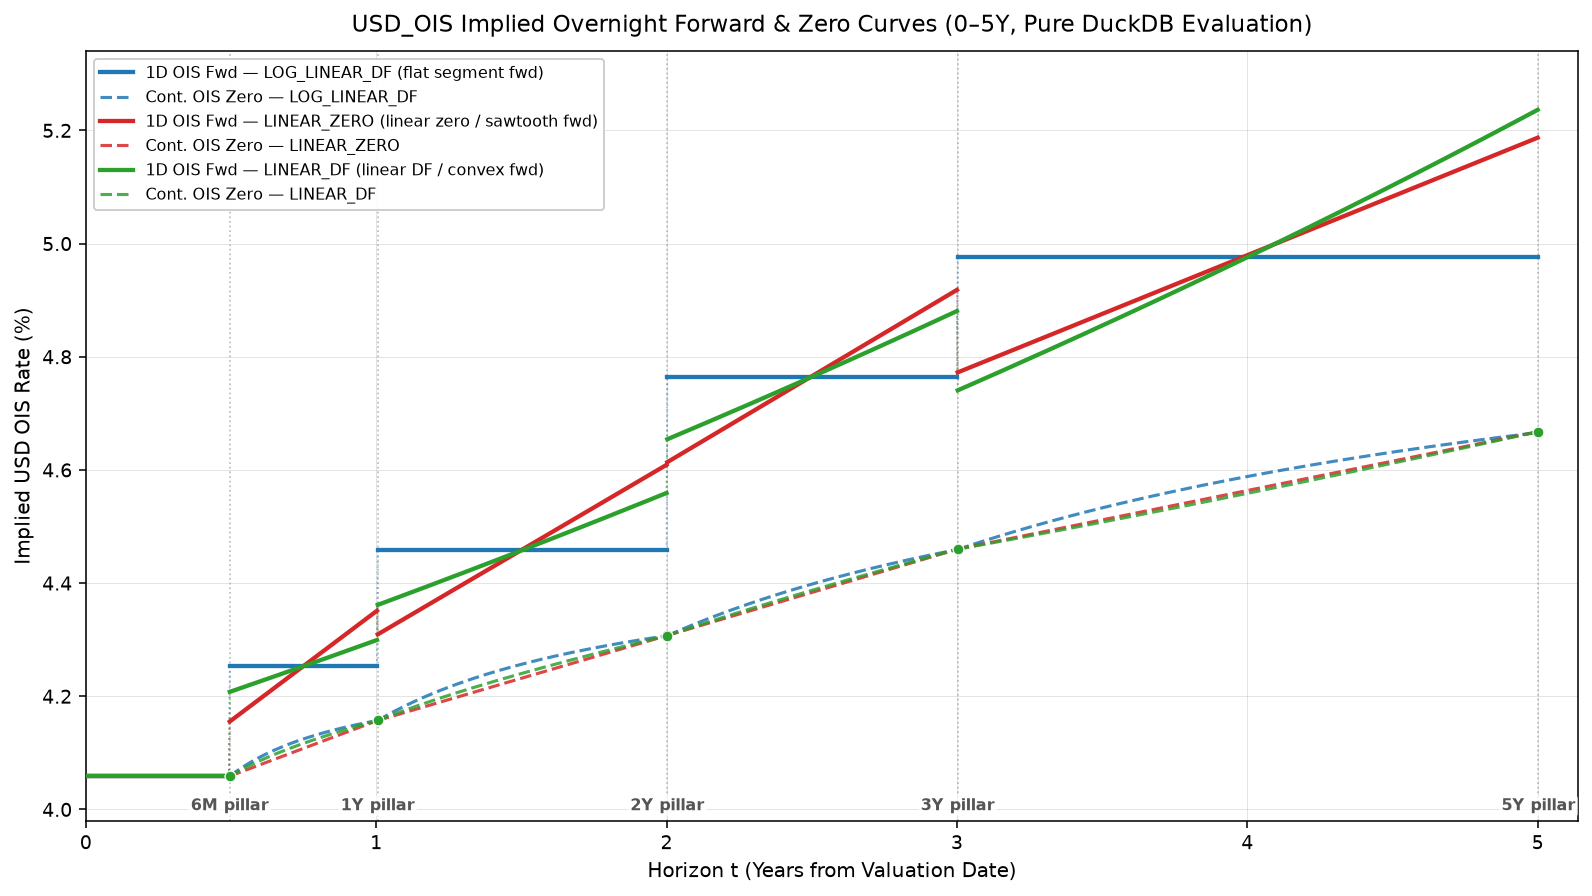

0–5Y max cross-method spread: Zero rate = 3.02 bp | 1D Overnight OIS forward = 25.97 bp


In [4]:
import math

methods = ("LOG_LINEAR_DF", "LINEAR_ZERO", "LINEAR_DF")
styles = {
    "LOG_LINEAR_DF": ("#1f77b4", "LOG_LINEAR_DF (flat segment fwd)"),
    "LINEAR_ZERO":   ("#d62728", "LINEAR_ZERO (linear zero / sawtooth fwd)"),
    "LINEAR_DF":     ("#2ca02c", "LINEAR_DF (linear DF / convex fwd)"),
}

fitted_by_method = {
    m: [
        CurveKnot(m, k.curve_id, k.knot_idx, k.knot_t, k.zero_rate, m)
        for k in fit_zero_curve(benchmarks, VAL_DATE, HOLIDAYS, "USD_OIS", m)
    ]
    for m in methods
}
all_knots = [k for ks in fitted_by_method.values() for k in ks]

pillar_ts = [k.knot_t for k in fitted_by_method["LOG_LINEAR_DF"] if k.knot_t <= 5.05]
pillar_labels = ["6M", "1Y", "2Y", "3Y", "5Y"]
dt_1d = 1.0 / 365.0
bounds = [0.0] + pillar_ts

def _linspace(a: float, b: float, count: int) -> list[float]:
    return [a + (b - a) * k / (count - 1) for k in range(count)]

# Sample strictly inside each pillar interval so [t, t + 1d] never straddles a knot discontinuity
seg_grids = [
    _linspace(max(2e-3, bounds[i] + 1e-5), bounds[i + 1] - dt_1d - 1e-5, 65)
    for i in range(len(bounds) - 1)
]
eval_times = sorted({float(t) for g in seg_grids for t in g} | {float(t + dt_1d) for g in seg_grids for t in g})
time_key = {t: f"T_{idx:04d}" for idx, t in enumerate(eval_times)}

# Unit fixed cashflows (notional=1, dcf=1, rate=1) evaluate P(0, t) directly through Pure in DuckDB
probe_cfs = [
    CashflowRow(
        trade_id=tid, leg_id="DF", cf_idx=0, instrument_type="OIS", ccy="USD", csa="USD",
        discount_curve_id="USD_OIS", proj_curve_id="USD_OIS",
        accrual_start_t=0.0, accrual_end_t=t, pay_t=t, dcf=1.0,
        notional=1.0, fixed_rate=1.0, spread=0.0, is_float=False, pay_receive=1.0,
    )
    for t, tid in time_key.items()
]
pure_grid_dfs = run_pure_pricing_duckdb(all_knots, probe_cfs, projects_dir=PRICING_DIR)

t_plot: list[float] = []
zero_by_m: dict[str, list[float]] = {m: [] for m in methods}
fwd_by_m: dict[str, list[float]] = {m: [] for m in methods}
seg_fwd_ends: dict[str, list[tuple[float, float, float, float]]] = {m: [] for m in methods}

for g in seg_grids:
    for t in g:
        t_f = float(t)
        t_plot.append(t_f)
        for m in methods:
            df0 = pure_grid_dfs[(m, time_key[t_f], "USD", "USD")]
            df1 = pure_grid_dfs[(m, time_key[float(t + dt_1d)], "USD", "USD")]
            zero_by_m[m].append(-math.log(df0) / t_f * 100.0)
            fwd_by_m[m].append((df0 / df1 - 1.0) / dt_1d * 100.0)
    for m in methods:
        seg_fwd_ends[m].append((float(g[0]), fwd_by_m[m][-len(g)], float(g[-1]), fwd_by_m[m][-1]))
    t_plot.append(float("nan"))
    for m in methods:
        zero_by_m[m].append(float("nan"))
        fwd_by_m[m].append(float("nan"))

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11.5, 6.5), dpi=140)
    for t_p, lbl in zip(pillar_ts, pillar_labels):
        ax.axvline(t_p, color="#888888", linestyle=":", linewidth=0.9, alpha=0.55, zorder=1)
        ax.text(t_p, 3.992, f"{lbl} pillar", ha="center", va="bottom", fontsize=8.0,
                color="#555555", fontweight="bold",
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})
    for m in methods:
        color, label = styles[m]
        ax.plot(t_plot, fwd_by_m[m], color=color, linewidth=2.2, linestyle="-", label=f"1D OIS Fwd — {label}", zorder=3)
        for idx_s in range(len(seg_fwd_ends[m]) - 1):
            _, _, t_r, f_r = seg_fwd_ends[m][idx_s]
            t_l, f_l, _, _ = seg_fwd_ends[m][idx_s + 1]
            ax.plot([t_r, t_l], [f_r, f_l], color=color, linewidth=1.0, linestyle=":", alpha=0.45, zorder=2)
        ax.plot(t_plot, zero_by_m[m], color=color, linewidth=1.6, linestyle="--", alpha=0.85, label=f"Cont. OIS Zero — {m}", zorder=2)
        ks_5y = [k for k in fitted_by_method[m] if k.knot_t <= 5.05]
        ax.scatter([k.knot_t for k in ks_5y], [k.zero_rate * 100.0 for k in ks_5y], color=color, s=30, zorder=4, edgecolors="white", linewidths=0.5)
    ax.set_xlim(0.0, 5.14)
    ax.set_ylim(3.98, 5.34)
    ax.set_xlabel("Horizon t (Years from Valuation Date)", fontsize=10.5)
    ax.set_ylabel("Implied USD OIS Rate (%)", fontsize=10.5)
    ax.set_title("USD_OIS Implied Overnight Forward & Zero Curves (0–5Y, Pure DuckDB Evaluation)", fontsize=12, pad=10)
    ax.grid(True, linestyle="-", linewidth=0.5, alpha=0.35)
    ax.legend(loc="upper left", fontsize=8.3, ncol=1, framealpha=0.95)
    fig.tight_layout()
    plt.show()
except ImportError:
    pass

valid_idx = [i for i, t in enumerate(t_plot) if not math.isnan(t)]
max_zero_bp = max((max(zero_by_m[m][i] for m in methods) - min(zero_by_m[m][i] for m in methods)) * 100 for i in valid_idx)
max_fwd_bp = max((max(fwd_by_m[m][i] for m in methods) - min(fwd_by_m[m][i] for m in methods)) * 100 for i in valid_idx)
print(f"0–5Y max cross-method spread: Zero rate = {max_zero_bp:.2f} bp | 1D Overnight OIS forward = {max_fwd_bp:.2f} bp")

## Step 4: Risk Scenarios & Why a Benchmark Swap Has Risk Strictly in Its Own Bucket

In PR 2, Pure (`pricing::cashflowPvs()`) reprices all `(scenarioId, tradeId)` pairs in `PR_CURVE_KNOT` in a single SQL pass, while Python constructs the scenario curves:
- **Zero-Knot Bump (`build_curve_scenarios`)**: bumps a single calibrated `zero_rate` knot $r_k \pm 1\text{ bp}$ holding other zero rates fixed — intermediate coupons of a 5Y swap discount off earlier zero knots (`6M..3Y`), producing small off-bucket zero-rate sensitivities.
- **Par-Quote Bucket Scenarios (recalibrated benchmark bumps)**: bumps each market OIS swap quote $q_k \pm 1\text{ bp}$ and re-fits `PR_CURVE_KNOT`. Because every unbumped benchmark swap still calibrates to par (`NPV = 0`), **a benchmark swap portfolio has 100% of its DV01 in its own tenor bucket (`0.00` in every other bucket)** across all three interpolation methods.

LOG_LINEAR_DF | $10M 5Y Benchmark Swap Par-Bucket DV01: {'6M': -0.0, '1Y': -0.0, '2Y': -0.0, '3Y': -0.0, '5Y': 4429.56, '7Y': 0.0, '10Y': 0.0}  (max off-bucket=$8.36e-08)


LINEAR_ZERO   | $10M 5Y Benchmark Swap Par-Bucket DV01: {'6M': -0.0, '1Y': -0.0, '2Y': -0.0, '3Y': -0.0, '5Y': 4430.87, '7Y': 0.0, '10Y': 0.0}  (max off-bucket=$6.49e-08)


LINEAR_DF     | $10M 5Y Benchmark Swap Par-Bucket DV01: {'6M': -0.0, '1Y': -0.0, '2Y': -0.0, '3Y': -0.0, '5Y': 4430.98, '7Y': 0.0, '10Y': 0.0}  (max off-bucket=$5.89e-08)



Full 7x7 Benchmark Portfolio Par-Bucket DV01 Matrix ($1M notional each, Pure DuckDB):
Trade   |       6M       1Y       2Y       3Y       5Y       7Y      10Y
------------------------------------------------------------------------
BM_6M   |    48.60     0.00     0.00     0.00     0.00     0.00     0.00
BM_1Y   |     0.00    97.47     0.00     0.00     0.00     0.00     0.00
BM_2Y   |     0.00     0.00   189.99     0.00     0.00     0.00     0.00
BM_3Y   |     0.00     0.00     0.00   278.51     0.00     0.00     0.00
BM_5Y   |     0.00     0.00     0.00     0.00   442.96     0.00     0.00
BM_7Y   |     0.00     0.00     0.00     0.00     0.00   591.74     0.00
BM_10Y  |     0.00     0.00     0.00     0.00     0.00     0.00   786.46


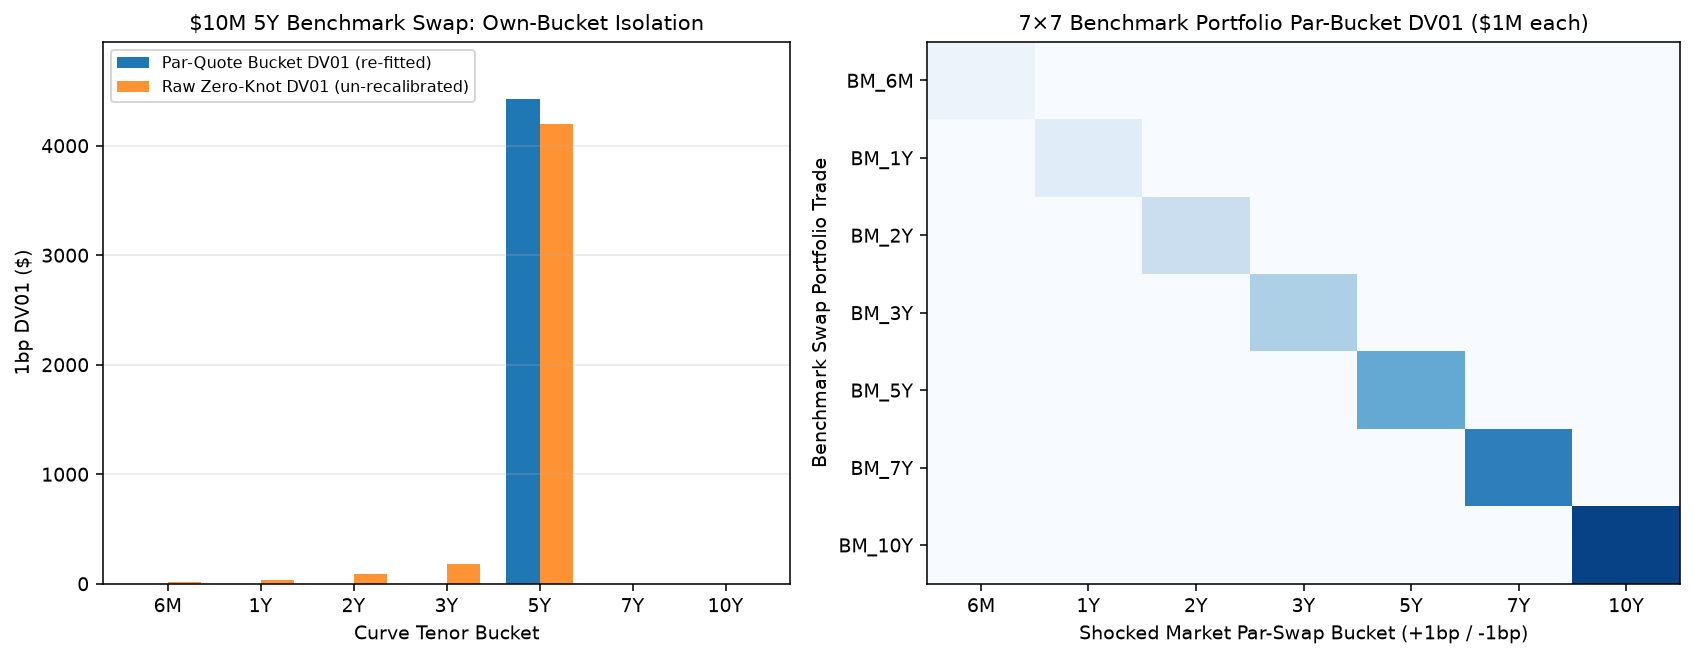

In [5]:
import dataclasses

def build_par_quote_scenarios(
    benchmark_swaps: list[SwapSpec],
    val_date: dt.date,
    holidays: set[dt.date],
    curve_id: str,
    interp_method: str,
    bump_bp: float = 1.0,
) -> list[CurveKnot]:
    """Bump each benchmark par quote +/- bump_bp and re-fit PR_CURVE_KNOT scenarios."""
    bump = bump_bp * 1e-4
    base = fit_zero_curve(benchmark_swaps, val_date, holidays, curve_id, interp_method)
    out = list(base)
    for j in range(len(benchmark_swaps)):
        for sign, tag in ((1.0, "UP"), (-1.0, "DN")):
            shocked = [
                dataclasses.replace(sw, fixed_rate=sw.fixed_rate + (sign * bump if idx == j else 0.0))
                for idx, sw in enumerate(benchmark_swaps)
            ]
            scen_id = f"BUMP_{curve_id}_{j}_{tag}"
            for k in fit_zero_curve(shocked, val_date, holidays, curve_id, interp_method):
                out.append(CurveKnot(scen_id, k.curve_id, k.knot_idx, k.knot_t, k.zero_rate, k.interp_method))
    return out

# 1) Single-benchmark portfolio ($10M 5Y par OIS swap) + full 7-benchmark rack ($1M each)
bm_5y_10m = dataclasses.replace(benchmarks[4], trade_id="PF_BM_5Y_10M", notional=10_000_000.0)
all_bm_cfs = expand_swap_to_cashflows(bm_5y_10m, VAL_DATE, HOLIDAYS) + [
    cf for bm in benchmarks for cf in expand_swap_to_cashflows(bm, VAL_DATE, HOLIDAYS)
]
bucket_names = [bm.trade_id.replace("BM_", "") for bm in benchmarks]

for method in methods:
    q_knots = build_par_quote_scenarios(benchmarks, VAL_DATE, HOLIDAYS, "USD_OIS", method, bump_bp=1.0)
    q_base = [k for k in q_knots if k.scenario_id == "BASE"]
    q_npvs = run_pure_pricing_duckdb(q_knots, all_bm_cfs, projects_dir=PRICING_DIR)
    q_dv01 = compute_bump_dv01_python(q_npvs, q_base)

    off_diag = max(
        abs(q_dv01[(bm.trade_id, "USD", "USD", "USD_OIS", j)])
        for i, bm in enumerate(benchmarks)
        for j in range(len(benchmarks))
        if i != j
    )
    assert off_diag < 1e-6, f"{method} unexpected off-bucket DV01: {off_diag}"
    pf5_buckets = {bucket_names[j]: round(q_dv01[("PF_BM_5Y_10M", "USD", "USD", "USD_OIS", j)], 2) for j in range(len(benchmarks))}
    print(f"{method:13s} | $10M 5Y Benchmark Swap Par-Bucket DV01: {pf5_buckets}  (max off-bucket=${off_diag:.2e})")

# Detailed comparison & visual under LOG_LINEAR_DF
q_knots_ll = build_par_quote_scenarios(benchmarks, VAL_DATE, HOLIDAYS, "USD_OIS", "LOG_LINEAR_DF", bump_bp=1.0)
q_base_ll = [k for k in q_knots_ll if k.scenario_id == "BASE"]
q_dv01_ll = compute_bump_dv01_python(run_pure_pricing_duckdb(q_knots_ll, all_bm_cfs, projects_dir=PRICING_DIR), q_base_ll)

z_knots_ll = build_curve_scenarios(q_base_ll, bump_bp=1.0)
z_dv01_ll = compute_bump_dv01_python(run_pure_pricing_duckdb(z_knots_ll, all_bm_cfs, projects_dir=PRICING_DIR), q_base_ll)

print("\nFull 7x7 Benchmark Portfolio Par-Bucket DV01 Matrix ($1M notional each, Pure DuckDB):")
hdr = "Trade   | " + " ".join(f"{b:>8s}" for b in bucket_names)
print(hdr)
print("-" * len(hdr))
mat = [[0.0] * len(benchmarks) for _ in range(len(benchmarks))]
for i, bm in enumerate(benchmarks):
    for j in range(len(benchmarks)):
        val = q_dv01_ll[(bm.trade_id, "USD", "USD", "USD_OIS", j)]
        mat[i][j] = 0.0 if abs(val) < 1e-6 else val
    print(f"{bm.trade_id:7s} | " + " ".join(f"{mat[i][j]:8.2f}" for j in range(len(benchmarks))))

try:
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.8), dpi=140, gridspec_kw={"width_ratios": [1.05, 1.15]})
    x = list(range(len(bucket_names)))
    w_bar = 0.36
    par_bars = [q_dv01_ll[("PF_BM_5Y_10M", "USD", "USD", "USD_OIS", j)] for j in range(len(bucket_names))]
    zero_bars = [z_dv01_ll[("PF_BM_5Y_10M", "USD", "USD", "USD_OIS", j)] for j in range(len(bucket_names))]
    ax1.bar([xi - w_bar / 2 for xi in x], par_bars, width=w_bar, color="#1f77b4", label="Par-Quote Bucket DV01 (re-fitted)")
    ax1.bar([xi + w_bar / 2 for xi in x], zero_bars, width=w_bar, color="#ff7f0e", alpha=0.85, label="Raw Zero-Knot DV01 (un-recalibrated)")
    ax1.set_xticks(x, bucket_names)
    ax1.set_ylim(0, 4950)
    ax1.set_xlabel("Curve Tenor Bucket", fontsize=10)
    ax1.set_ylabel("1bp DV01 ($)", fontsize=10)
    ax1.set_title("$10M 5Y Benchmark Swap: Own-Bucket Isolation", fontsize=10.8)
    ax1.grid(True, axis="y", alpha=0.3)
    ax1.legend(loc="upper left", fontsize=8.2)
    max_mat = max(max(row) for row in mat)
    ax2.imshow(mat, cmap="Blues", aspect="auto", vmin=0.0, vmax=float(max_mat) * 1.08)
    ax2.set_xticks(x, bucket_names)
    ax2.set_yticks(x, [bm.trade_id for bm in benchmarks])
    ax2.set_xlabel("Shocked Market Par-Swap Bucket (+1bp / -1bp)", fontsize=10)
    ax2.set_ylabel("Benchmark Swap Portfolio Trade", fontsize=10)
    ax2.set_title("7×7 Benchmark Portfolio Par-Bucket DV01 ($1M each)", fontsize=10.8)
    fig.tight_layout()
    plt.show()
except ImportError:
    pass